In [1]:
import time
import h5py
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt
import sys
from scipy import stats as st
sys.path.append('/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/')

from chemrixs.smalldata import SmallData
from chemrixs.utils import *
from pathlib import Path
# %matplotlib widget 

## Create the SmallData Object

In [5]:

# --- config ---
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 67              # subsample for speed
fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
fyaml = '../roi_input.yml'   

small_data = SmallData(fname, fyaml)

In [6]:
small_data.open()
dir(small_data)

['_SmallData__file',
 '_SmallData__intgrp',
 '_SmallData__ssgrp',
 '__class__',
 '__del__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__enter__',
 '__eq__',
 '__exit__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 'close',
 'epics',
 'integrating',
 'is_open',
 'open',
 'path',
 'run',
 'runinfo',
 'scantype',
 'singleshot',
 'yaml']

In [ ]:
dir(small_data.integrating)

<KeysViewHDF5 ['lxt_ttc', 'step_value']>
67
setting up properties
dataset prop <functools.cached_property object at 0x7f7aeca60f90>
dataset prop <functools.cached_property object at 0x7f7aee35b310>
dataset prop <functools.cached_property object at 0x7f7aeca60d90>
dataset prop <functools.cached_property object at 0x7f7aeca61c50>
dataset prop <functools.cached_property object at 0x7f7b24da3410>
dataset prop <functools.cached_property object at 0x7f7aeca60bd0>
dataset prop <functools.cached_property object at 0x7f7aeca60890>
dataset prop <functools.cached_property object at 0x7f7aeca60690>
dataset prop <functools.cached_property object at 0x7f7aeca60a50>


### Mono Encoder Sum

<KeysViewHDF5 ['c_piranha_sum_full_area', 'count', 'crix_w8_sum_base_0', 'crix_w8_sum_base_1', 'crix_w8_sum_base_2', 'crix_w8_sum_base_3', 'crix_w8_sum_base_4', 'crix_w8_sum_base_5', 'crix_w8_sum_base_6', 'crix_w8_sum_base_7', 'crix_w8_sum_base_all', 'crix_w8_sum_integral_0', 'crix_w8_sum_integral_1', 'crix_w8_sum_integral_2', 'crix_w8_sum_integral_3', 'crix_w8_sum_integral_4', 'crix_w8_sum_integral_5', 'crix_w8_sum_integral_6', 'crix_w8_sum_integral_7', 'crix_w8_sum_integral_all', 'crix_w8_sum_intensity', 'crix_w8_sum_itrigCount', 'crix_w8_sum_posX', 'crix_w8_sum_posY', 'crix_w8_sum_ptrigCount', 'det_crix_w8_sum_full_area', 'det_crix_w8_sum_wfintegrate', 'det_rix_fim0_sum_full_area', 'det_rix_fim0_sum_wfintegrate', 'det_rix_fim1_sum_full_area', 'det_rix_fim1_sum_wfintegrate', 'droplet_dense_curve_corr_corrected_image', 'droplet_dense_curve_corr_pj_ax_1_data', 'droplet_nDroplets', 'droplet_nDroplets_all', 'fzp_piranha_sum_full_area', 'lightStatus_sum_laser', 'lightStatus_sum_xray', 'mo

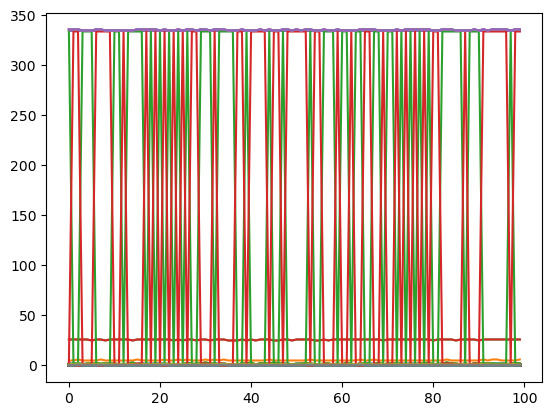

In [ ]:
with h5py.File(fname, 'r') as f:
    axis_svls = f['intg/axis_svls']
    print(axis_svls.keys())
    event_codes = axis_svls['timing_sum_eventcodes'][:]
    mono_sum = axis_svls['mono_hrencoder_sum_value'][:]  
    light_status = axis_svls['lightStatus_sum_laser'][:]
    print(mono_sum.shape)
    print()
    print(light_status[1000:1400])
    laser_off
plt.figure()
plt.plot(event_codes[100:200])
plt.show()

In [12]:
with h5py.File(fname, 'r') as f:
    axis_svls = f['Sums']
    print(axis_svls.keys())

<KeysViewHDF5 ['c_atmopal_calib', 'c_piranha_calib', 'det_crix_w8_calib', 'det_rix_fim0_calib', 'det_rix_fim1_calib', 'fzp_piranha_calib']>


335


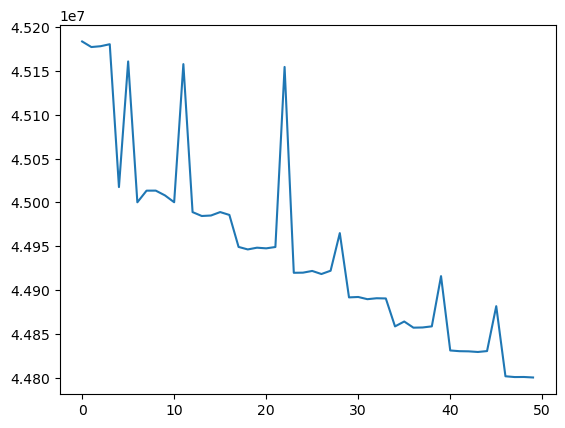

In [ ]:
with h5py.File(fname, 'r') as f:
    g = f['intg/axis_svls']
    count   = g['count'][:].squeeze()
    monoenc = g['mono_hrencoder_sum_value'][:].squeeze()
    fim0_wf = g['det_rix_fim0_sum_full_area'][:]
    fim1_wf = g['det_rix_fim1_sum_full_area'][:]
    print(g.keys())


# ---- count mask: keep frames with the expected number of shots ----
mode_c = st.mode(count, keepdims=False)[0]
print(mode_c)
cmask  = (count > mode_c-2) & (count < mode_c+2)
plt.figure()
x = list(range(len(monoenc[0:50])))
plt.plot(x, monoenc[0:50])
plt.show()

### Laser on and off shots

In [27]:
import scipy.stats as st
with h5py.File(fname, 'r') as f:
    axis_svls = f['intg/axis_svls']
    light_status = axis_svls['lightStatus_sum_laser'][:]
    count = axis_svls['count'][:]


print(st.mode(count))
laser_on = light_status == 334
laser_off = light_status == 0



unique, counts = np.unique(light_status, return_counts=True)
for val, cnt in zip(unique, counts):
    print(f"lightStatus value {val}: {cnt} bins")

laser_on = light_status == 334
laser_off = light_status <= 2
print(sum(laser_on))
print(sum(laser_off))


ModeResult(mode=335, count=15831)
lightStatus value 1: 7917 bins
lightStatus value 2: 6784 bins
lightStatus value 333: 5 bins
lightStatus value 334: 14695 bins
14695
14701


In [46]:
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 120
fyaml = '../roi_input.yml'                        

fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5' 

runs_with_andor = [61, 62, 63, 64, 65, 66, 67, 68, 69, 71, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84]

# extract detector data directly from h5 file
with h5py.File(fname, 'r') as h5:
    g       = h5['intg/axis_svls']
    count   = g['count'][:].squeeze()
    light_status = g['lightStatus_sum_laser'][:]
    monoenc = g['mono_hrencoder_sum_value'][:].squeeze()
    fim0_wf = g['det_rix_fim0_sum_full_area'][:]
    fim1_wf = g['det_rix_fim1_sum_full_area'][:]
    svls_proj = g['droplet_dense_curve_corr_pj_ax_1_data'][:]
    apd_wf = g['det_crix_w8_sum_full_area'][:]
    fzp = g['fzp_piranha_sum_full_area'][:]
    if run in runs_with_andor:
        andor_full = h5['intg/andor_dir/full_area'][:]


### Plot the Transmission

(28931, 2048)
[7687, 8088, 7443, 7501, 7215, 8159, 7483, 7342, 7876, 8210, 7783, 7567, 7234, 8476, 7895, 7717, 8335, 8734, 8669, 8653, 8471, 9702, 8816, 8737, 8531, 9550, 8626, 8851, 9122, 9684, 10209, 10313, 10210, 11313, 10554, 10904, 11446, 12714, 12928, 14511, 14578, 17126, 17387, 18577, 19270, 20326, 19135, 20423, 19624, 20794, 19706, 20018, 20873, 23371, 24690, 30026, 35263, 45374, 55798, 69081, 82924, 95784, 108195, 123715, 132472, 133880, 129555, 134141, 144757, 155237, 158033, 160650, 157407, 156219, 153049, 150093, 144003, 136805, 129038, 122749, 114979, 107802, 97905, 89007, 81349, 77160, 72244, 69375, 65077, 61304, 56599, 51897, 47537, 44409, 40584, 36950, 33454, 31379, 28880, 26115, 23510, 22162, 20569, 19689, 18139, 18160, 17074, 15513, 14869, 14401, 12539, 11919, 11914, 11968, 10838, 10198, 9851, 9980, 9249, 9155, 8607, 9062, 7751, 8264, 7799, 7930, 7614, 8218, 8112, 8213, 6620, 7334, 7333, 7546, 7179, 7907, 7568, 7744, 6419, 6948, 7461, 7312, 6675, 7733, 7039, 7505, 593

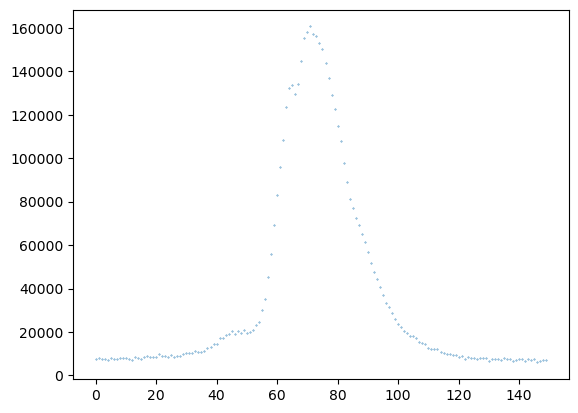

In [47]:
print(fzp.shape)
fzp_slice = fzp[100,1000:1150]
fzp_sum = fzp.sum(axis = 0)
with np.printoptions(threshold=np.inf):
    num_list = []
    [num_list.append(x) for x in fzp_slice]
    print(num_list)
plt.figure()
x = np.array(list(range(len(fzp_slice))))
x = x 

plt.scatter(x, fzp_slice, s = 0.1)
plt.show()